# 04 · Tender notices, and can they be linked to contracts?

**Stage 2, checklist question 5.** Dashboard page 5 (tender pipeline) and the tender-to-contract link depend on the
tender files. Tender notices carry no dollar value, so the questions here are about grain, coverage and keys:

1. What does one tender row represent?
2. Who posts tenders, compared with who awards the contracts in the contract files?
3. Which fields could link a contract to its tender, and how often does an exact match occur?

The match rates below are a **first look** with exact matching on trimmed values. Stage 3 measures the link properly.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from spendpipe import sources as S, eda
eda.apply_style()
pd.set_option("display.max_columns", 30, "display.width", 160, "display.max_colwidth", 60)

In [2]:
import re
tenders =S.parse_types(pd.concat([S.load("tenders_legacy"), S.load("tenders_current")], ignore_index=True))
contracts = pd.concat([S.load("contracts_legacy"), S.load("contracts_current")], ignore_index=True)
tenders.groupby("source").agg(rows=("reference_number", "size"), references=("reference_number", "nunique"),
                              solicitations=("solicitation_number", "nunique"),
                              first_published=("publication_date", "min"), last_published=("publication_date", "max"))

,rows,references,solicitations,first_published,last_published
source,,,,,
tenders_current,30830,30830,28062,2022-08-08,2026-10-22
tenders_legacy,71310,71310,70083,2010-03-16,2022-08-05


## 1. Grain

Every row has its own reference number. Rows that share a solicitation number: are they amendments of one notice,
or separate notices?

In [3]:
shared = tenders[tenders.solicitation_number.duplicated(keep=False) & tenders.solicitation_number.notna()]
print(f"rows sharing a solicitation number: {len(shared):,} ({shared.solicitation_number.nunique():,} solicitation numbers)")
print("most common shared values:", shared.solicitation_number.value_counts().head(5).to_dict())
real = shared[shared.solicitation_number.str.len() > 3]
real.sort_values(["solicitation_number", "publication_date"])[
    ["solicitation_number", "reference_number", "amendment_number", "publication_date", "tender_status", "title"]].head(8)

rows sharing a solicitation number: 7,652 (3,446 solicitation numbers)
most common shared values: {'WS3753315787': 14, 'WS4556634926': 13, 'WS5802684496': 13, 'WS3930664986': 12, 'WS3971410438': 12}


,solicitation_number,reference_number,amendment_number,publication_date,tender_status,title
60943,000154,PW-20-00915291,001,2020-05-21,Expired,The Provision of Quality Assurance and Accessibility Man...
61976,000154,PW-20-00925787,001,2020-09-10,Expired,Request for Proposals (RFP) for the Provision of Quality...
60,000849,PW-15-00676738,000,2015-03-19,Expired,"ADVANCE PROCUREMENT NOTICE-CONSTRUCTION OF AN ARMOURY, 3..."
61,000849,PW-15-00682397,000,2015-05-01,Expired,"ADVANCE PROCUREMENT NOTICE-CONSTRUCTION OF AN ARMOURY, 3..."
47075,00754048,PW-16-00754048,005,2016-10-31,Expired,Video Conferencing Procurement Vehicle (VCPV) - Industry...
49303,00754048,PW-17-00786773,003,2017-09-29,Expired,Videoconference Procurement Vehicle (VCPV) 00754048/B
16717,01581-210906/A,PW-_CAL-148-7188,000,2021-02-25,Cancelled,Cancelled-01581-210906/A
64303,01581-210906/A,PW-_CAL-148-7187,000,2021-02-26,Cancelled,Cancelled-01581-210906/A


In [4]:
print("tender status by file (%):")
print((pd.crosstab(tenders.tender_status, tenders.source, normalize="columns") * 100).round(1))
print("\namendment number on each row (share that are 000):",
      tenders.groupby("source").amendment_number.apply(lambda s: f"{s.eq('000').mean():.1%}").to_dict())

tender status by file (%):
source         tenders_current  tenders_legacy
tender_status                                 
Cancelled                  6.6             3.6
Expired                   90.6            96.4
Open                       2.8             0.0

amendment number on each row (share that are 000): {'tenders_current': '16.2%', 'tenders_legacy': '48.6%'}


## 2. Who posts tenders vs who awards contracts?

In [5]:
pspc = lambda s: s.str.contains("Public Works|PSPC|Public Services and Procurement", case=False, na=False)
print("contract rows awarded by PSPC:", f"{pspc(contracts.contracting_entity).mean():.1%}")
share = tenders.groupby("source").contracting_entity.apply(lambda s: pspc(s).mean())
print("tender notices posted by PSPC:", share.map("{:.1%}".format).to_dict())
tenders.contracting_entity.value_counts().head(10).to_frame("notices (both files)")

contract rows awarded by PSPC: 100.0%
tender notices posted by PSPC: {'tenders_current': '37.9%', 'tenders_legacy': '58.0%'}


,notices (both files)
contracting_entity,
Public Works and Government Services Canada,41463
Department of Public Works and Government Services (PSPC),11471
Department of National Defence,6266
Shared Services Canada,2819
Fisheries and Oceans Canada,2562
Parks Canada,2408
Department of National Defence (DND),2368
Royal Canadian Mounted Police,2365
Correctional Service of Canada,2288


## 3. Keys that could link a contract to its tender

Candidates: the contract's `solicitation_number` or its `procurement_number` (the contract number without its
`/001/XX` suffix), matched against tender solicitation numbers. Reference numbers are notice IDs (notebook 01),
so they are tested only to confirm they never match. A solicitation number is counted only if it is longer than
3 characters, which excludes placeholders such as `-`.

In [6]:
tsol = set(tenders.solicitation_number.dropna()[lambda s: s.str.len() > 3])
tref = set(tenders.reference_number.dropna())
first = S.first_rows(contracts)
first["system"] = S.record_system(first.contracting_entity)
first["award_fy"] = pd.to_datetime(first.award_date).pipe(lambda d: d.dt.year - (d.dt.month < 4)).astype("Int64")
first["by_solicitation"] = first.solicitation_number.isin(tsol)
first["by_procurement_number"] = first.procurement_number.isin(tsol)
first["either"] = first.by_solicitation | first.by_procurement_number
first["reference"] = first.index.isin(tref) | first.reference_number.isin(tref)
first.groupby("system")[["by_solicitation", "by_procurement_number", "either", "reference"]].mean().mul(100).round(1)

,by_solicitation,by_procurement_number,either,reference
system,,,,
new,54.7,54.7,54.7,0.0
old,0.0,0.3,0.3,0.0


Old-system contracts almost never match. But legacy tender solicitation numbers often end in a letter suffix
(`01581-210906/A`), while old-system procurement numbers do not (`01581-210906`). **Exploratory test:** strip a
trailing `/` + letters from tender solicitation numbers and match again. This is not yet a linking rule. Stage 3
would have to check the matches it finds (same buyer, sensible dates) before trusting it.

In [7]:
stripped = {s.rsplit("/", 1)[0] if re.search(r"/[A-Z]{1,2}$", s) else s for s in tsol}
print(f"tender solicitation numbers ending in /letter(s): {sum(bool(re.search(r'/[A-Z]{1,2}$', s)) for s in tsol):,} of {len(tsol):,}")
first["by_stripped_suffix"] = first.procurement_number.isin(stripped)
first["either"] = first.by_solicitation | first.by_procurement_number | first.by_stripped_suffix
first.groupby("system")[["by_procurement_number", "by_stripped_suffix", "either"]].mean().mul(100).round(1)

tender solicitation numbers ending in /letter(s): 50,115 of 97,837


,by_procurement_number,by_stripped_suffix,either
system,,,
new,54.7,61.6,61.6
old,0.3,29.7,29.7


In [8]:
# a few matched pairs, to eyeball whether they are plausibly the same procurement
sol_lookup = tenders.dropna(subset=["solicitation_number"]).assign(
    key=lambda t: t.solicitation_number.str.replace(r"/[A-Z]{1,2}$", "", regex=True)).drop_duplicates("key").set_index("key")
hits = first[first.by_stripped_suffix & ~first.by_procurement_number & (first.system == "old")].head(5)
pd.DataFrame({"contract": hits.index, "contract title": hits.title.str[:45].values,
              "award": hits.award_date.values,
              "tender title": sol_lookup.loc[hits.procurement_number, "title"].str[:45].values,
              "tender published": sol_lookup.loc[hits.procurement_number, "publication_date"].dt.date.values})

,contract,contract title,award,tender title,tender published
0,01005-150086/001/WPG,BOBCAT OF REGINA LTD (01005-150086/001/WPG~00,2014-11-14,Skid Steer Loader,2014-09-24
1,01005-150132/001/WPG,WINACOTT EQUIPMENT GROUP (01005-150132/001/WP,2014-12-19,Highway Tractor,2014-10-07
2,01005-150240/001/WPG,REDHEAD EQUIPMENT LTD (01005-150240/001/WPG~0,2015-01-14,Custom Gravel Trailer,2014-11-19
3,01005-160089/001/WPG,POLAR BEAR EQUIPMENT LTD (01005-160089/001/WP,2016-01-27,Rain Shelters,2015-07-14
4,01005-160561/001/VAN,FARMCO SALES LTD (01005-160561/001/VAN~000),2016-01-26,Harvesting Equipment,2015-12-04


years with fewer than 100 contracts in a system are hidden


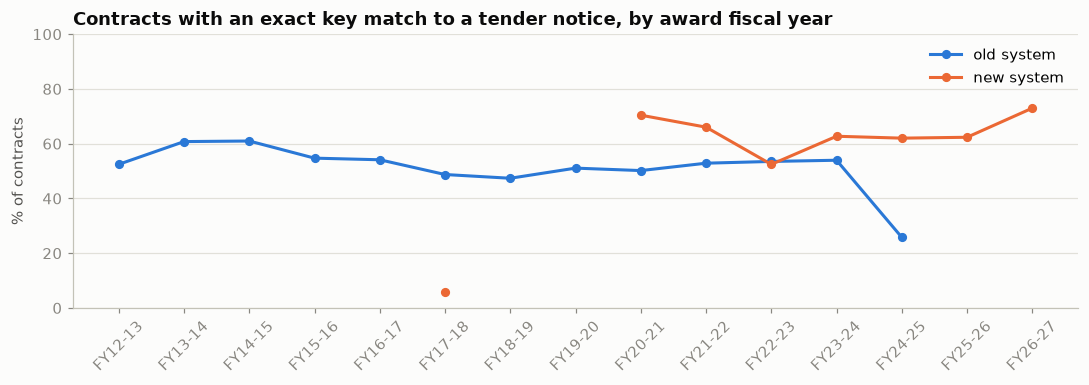

In [9]:
rate = first[first.award_fy.between(2012, 2026)].groupby(["award_fy", "system"]).either.mean().unstack("system") * 100
fig, ax = plt.subplots(figsize=(10, 3.6))
for sys_ in ["old", "new"]:
    n = first[first.system == sys_].groupby("award_fy").size().reindex(rate.index)
    s = rate[sys_].where(n >= 100)          # hide tiny groups; NaN breaks the line instead of bridging the gap
    ax.plot(rate.index.astype(int), s.values, marker="o", markersize=5, color=eda.SYSTEM_COLORS[sys_], label=f"{sys_} system")
ax.set_ylim(0, 100)
ax.set_ylabel("% of contracts")
ax.set_title("Contracts with an exact key match to a tender notice, by award fiscal year")
ax.set_xticks(rate.index.astype(int), [f"FY{int(y) % 100:02d}-{(int(y) + 1) % 100:02d}" for y in rate.index], rotation=45)
ax.legend()
fig.tight_layout()
print("years with fewer than 100 contracts in a system are hidden")

## Findings

1. **Grain:** every tender row has its own reference number (102,140 rows, all unique), so a row is a notice.
   7,652 rows share a solicitation number with another row: sometimes re-posts or follow-up notices for the same
   procurement, sometimes placeholders. The current file's `amendmentNumber` is `000` on only 16.2% of rows,
   which suggests a row shows the latest amendment of a notice rather than its original. To confirm in stage 3.
2. **Different populations:** every contract row is PSPC-awarded, but PSPC posted only 58.0% (legacy) and 37.9%
   (current) of tender notices. Tender analysis covers all departments; contract analysis covers PSPC only.
3. **Status:** 6.6% of current and 3.6% of legacy notices are cancelled; 2.8% of current notices are open.
4. **Linking keys.** Reference numbers never match a contract. An exact match on solicitation or procurement number
   links 54.7% of new-system contracts but only 0.3% of old-system ones. **Stripping the letter suffix from tender
   solicitation numbers** (`01581-210906/A` -> `01581-210906`) raises this to 61.6% (new) and 29.7% (old). From
   FY2012-13 onwards, when tender data exists, old-system contracts match at about 50-60%, similar to new-system ones.
   Sample matches look plausible (same goods, tender published before award).
5. **Caveats:** a key match is not yet proof of the same procurement, and many contracts never had a public tender
   (non-competitive awards, call-ups), so 100% is not the ceiling. Stage 3 must validate matches (buyer, dates,
   method) before the link is used, and report the rate separately for competitive contracts.